In [1]:
from diyanLib.imports import *
from diyanLib.utils import convert_to_perc

Hello from Diyan Amin!
Set environment variable to false.
Imported diyanLib.data
Variable do_import is set to False. Set it to True using diyanLib.imports.do_import=True. Setting to false improves execution speed by NOT importing libraries
Imported diyanLib.utils


Trademark DiyanAmin 2026
https://github.com/DiyanAmin/diyanLib




In [2]:
(x_train,y_train), (x_test,y_test) = mnist.load_data()

In [3]:
print('-'*10,'Dataset Shapes','-'*10)

print('Training Data:')
print(f'\tx: {x_train.shape}')
print(f'\ty: {y_train.shape}')

print('Testing Data')
print(f'\tx: {x_test.shape}')
print(f'\ty: {y_test.shape}')
print('-'*(20+(len('Dataset Shapes')+2)))

---------- Dataset Shapes ----------
Training Data:
	x: (60000, 28, 28)
	y: (60000,)
Testing Data
	x: (10000, 28, 28)
	y: (10000,)
------------------------------------


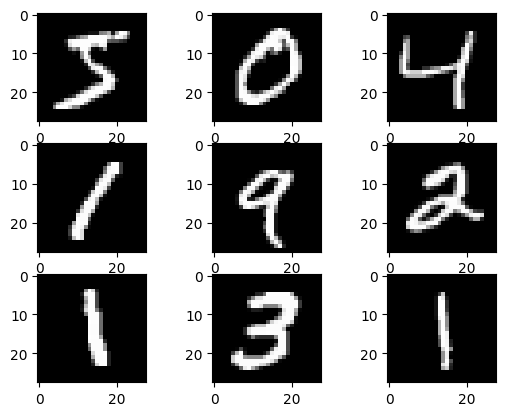

In [4]:
for i in range(9):
    plt.subplot(331+i)
    plt.imshow(x_train[i],cmap=plt.get_cmap('gray'))

plt.show() 

In [5]:
train_size = 8000
test_size = 2000

x_train = x_train[:train_size]
y_train = y_train[:train_size]

x_test = x_test[:test_size]
y_test = y_test[:test_size]

x_train = x_train.reshape(x_train.shape[0],28,28,1)
x_test = x_test.reshape(x_test.shape[0],28,28,1)


input_shape=(28,28,1)
num_classes = 10

y_train = to_categorical(y_train,num_classes)
y_test = to_categorical(y_test,num_classes)

x_train = x_train.astype('float32')/255
x_test = x_test.astype('float32')/255

In [6]:
print('x_train shape:',x_train.shape)
print(x_train.shape[0],'train samples')
print(x_test.shape[0],'test samples')

x_train shape: (8000, 28, 28, 1)
8000 train samples
2000 test samples


In [7]:
batch_size = 128
epochs = 10

model=Sequential()

In [8]:
model.add(Input(shape=input_shape))

In [9]:
model.add(Conv2D(32,kernel_size=(3,3),activation='relu'))

In [10]:
model.add(MaxPooling2D(pool_size=(2,2)))

In [11]:
model.add(Flatten())

In [12]:
model.add(Dense(256,activation='relu'))

In [13]:
model.add(Dense(num_classes,activation='softmax'))

In [14]:
opt = SGD(learning_rate=.01)

In [15]:
model.compile(loss='categorical_crossentropy',optimizer=opt,metrics=['accuracy'])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,384,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,594 (5.29 MB)

 Trainable params: 1,387,594 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.fit(x_train,y_train,batch_size=batch_size,epochs=epochs,verbose=1,validation_data=(x_test,y_test))
print('Model has been successfully trained')

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4014 - loss: 2.1469 - val_accuracy: 0.6465 - val_loss: 1.9436
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7548 - loss: 1.5226 - val_accuracy: 0.7640 - val_loss: 1.2017
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8316 - loss: 0.8492 - val_accuracy: 0.8010 - val_loss: 0.7785
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8654 - loss: 0.5730 - val_accuracy: 0.8385 - val_loss: 0.6136
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8821 - loss: 0.4623 - val_accuracy: 0.8575 - val_loss: 0.5340
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8936 - loss: 0.4058 - val_accuracy: 0.8615 - val_loss: 0.4891
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9005 - loss: 0.3706 - val_accuracy: 0.8700 - val_loss: 0.4614
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9050 - loss: 0.3462 - val_accuracy: 0.8710 - v

In [18]:
model.save('mnist.keras')
print('Saving the model as mnist.keras.')

Saving the model as mnist.keras.


In [19]:
def print_fancy(title:str,display_data:dict):
    len_title = len([i for i in title])

    columns = list(display_data.keys())
    data = list(display_data.values())

    print('-'*10,title,'-'*10)

    for j in range(len(display_data)):
        print(f'\t{columns[j]}: {data[j]}')
    print('-'*(22+len_title))

In [20]:
score = model.evaluate(x_test,y_test,verbose=0)

print_fancy('Score',
            {
                'Test loss':convert_to_perc(score[0]),
                'Test accuracy': convert_to_perc(score[1])
            })

---------- Score ----------
	Test loss: 41.18%
	Test accuracy: 87.85%
---------------------------


In [21]:
def load_image(num:int):
    img = load_img(f'images\\test_{num}.png',color_mode='grayscale',target_size=(28,28))
    img = img_to_array(img)
    if img.mean()>127:
        img = 255-img
    img = img.reshape(1,28,28,1)
    img = img.astype('float32')/255

    return img

In [22]:
try:
    img=int(input('Enter image number: '))
    img = load_image(img)

    pred = model.predict(img)

    digit=argmax(pred)
    print('Predicted Digit:',digit)

except (ValueError,FileNotFoundError):
    print('Invalid number or file not found.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicted Digit: 3
